# Notebook 04 — Diagnostica Modello Adversarial Autoencoder (AAE)

> **Obiettivo:** analizzare in dettaglio le prestazioni e il comportamento diagnostico dell'Adversarial Autoencoder (`aae_final.pth`), valutare la qualità di ricostruzione vs baseline, la separabilità delle distribuzioni normale vs anomalo, l'allineamento dello spazio latente al prior $\mathcal{N}(0, I)$ imposto dal discriminatore e la calibrazione della soglia.

> **Principi guida:**
> - **Read-only:** niente modifiche a `src/`, `config/`, `data/processed/` o ai checkpoint salvati.
> - **Output solo a schermo:** nessun file o figura sovrascritti localmente.
> - **Seed fissato:** `set_seed(42)` da `src.utils.seed`.
> - **Prevalenza:** sempre mostrata accanto a ROC-AUC e PR-AUC.
> - **Test set:** usato solo per conferma finale, mai per calibrare soglie.
> - **Forma:** ogni sezione = 1 markdown (cosa/perché/come interpretare) + 1 codice (eseguibile autonomamente).
> - **Allineamento con AE:** identica struttura a sezioni del Notebook 04 dell'AE per confronto diretto 1-a-1.

## Sezione 0 — Setup globale

**Cosa:** carica la configurazione validata dell'AAE, i dati processati, i piani di partizione, istanzia i DataLoader con $W=32$, carica il checkpoint `aae_final.pth` e inizializza l'`AdversarialAutoencoder`.
**Perché:** tutte le analisi diagnostiche successive dipendono da questo modello e dagli split coerenti.
**Come interpretare:** il modello caricato riflette la configurazione multi-seed validata (Config 14, $W=32$, latent=16, $\lambda_{rec}=1.40$, $\lambda_{adv}=0.001$).

In [1]:
"""Sezione 0 — Setup globale: carica config, dati, modello AAE, loader."""
try:
    SEED
except NameError:
    SEED = 42

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

# --- Risoluzione robusta della root del progetto ---
try:
    PROJECT_ROOT = Path(__file__).resolve().parent.parent
except NameError:
    PROJECT_ROOT = Path("..").resolve()
    if not (PROJECT_ROOT / "data").exists():
        PROJECT_ROOT = Path(".").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# --- Moduli di progetto ---
from src.utils.seed import set_seed
set_seed(SEED)
from src.utils.config import load_config, get_param
from src.data.dataset import build_loader
from src.models.adversarial_ae import AdversarialAutoencoder

# --- Carica configurazione validata (config.yaml + params_validated.yaml) ---
config_path = PROJECT_ROOT / "config" / "config.yaml"
params_path = PROJECT_ROOT / "config" / "params_validated.yaml"
if not params_path.exists():
    params_path = PROJECT_ROOT / "config" / "params.yaml"
config = load_config(config_path=config_path, params_path=params_path)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Verifica e genera dati processati se mancanti ---
processed_dir = PROJECT_ROOT / "data" / "processed"
_required = [
    "normal_scaled.npy", "slow_scaled.npy",
    "plan_train.npy", "plan_val_normal.npy", "plan_val_anomaly.npy",
    "plan_test_normal.npy", "plan_test_anomaly.npy",
    "selected_columns.npy",
]
_missing = [f for f in _required if not (processed_dir / f).exists()]
if _missing:
    print(f"File processati mancanti: {_missing}. Eseguo preprocessing...")
    from src.data.preprocessing import run_preprocessing
    run_preprocessing(config)
    print("Preprocessing completato.")

# --- Carica dati processati ---
processed_dir = PROJECT_ROOT / "data" / "processed"
normal_arr = np.load(processed_dir / "normal_scaled.npy")
slow_arr = np.load(processed_dir / "slow_scaled.npy")

train_data = normal_arr
val_normal_data = normal_arr
val_anomaly_data = slow_arr
test_normal_data = normal_arr
test_anomaly_data = slow_arr

# --- Carica piani di partizione ---
train_starts_arr = np.load(processed_dir / "plan_train.npy")
val_normal_starts_arr = np.load(processed_dir / "plan_val_normal.npy")
val_anomaly_starts_arr = np.load(processed_dir / "plan_val_anomaly.npy")
test_normal_starts_arr = np.load(processed_dir / "plan_test_normal.npy")
test_anomaly_starts_arr = np.load(processed_dir / "plan_test_anomaly.npy")

selected_cols = np.load(processed_dir / "selected_columns.npy", allow_pickle=True)
feature_names = [str(c) for c in selected_cols]

# --- Carica checkpoint AAE ---
ckpt_path = PROJECT_ROOT / "reports" / "checkpoints" / "aae_final.pth"
if not ckpt_path.exists():
    ckpt_path = PROJECT_ROOT / "reports" / "checkpoints" / "aae_final_seed42.pth"

ckpt = torch.load(ckpt_path, map_location="cpu")
ckpt_sd = ckpt["model_state_dict"]
saved_threshold = ckpt.get("threshold", None)

# --- Iperparametri dalla configurazione validata (con default di sicurezza) ---
input_dim = int(get_param(config, "model.input_dim", 86))
latent_dim = int(get_param(config, "model.latent_dim", 16))
W = int(get_param(config, "data.window_size", 32))
batch_size = int(get_param(config, "training.batch_size", 256))
enc_channels = tuple(get_param(config, "model.encoder.conv_channels", [64, 32, 16]))
disc_hidden = tuple(get_param(config, "aae.discriminator.hidden_layers", [16, 8]))

# DataLoader
train_loader = build_loader(train_data, train_starts_arr, window_size=W,
                            batch_size=batch_size, label=0, shuffle=True, num_workers=0)
val_normal_loader = build_loader(val_normal_data, val_normal_starts_arr, window_size=W,
                                 batch_size=batch_size, label=0, num_workers=0)
val_anomaly_loader = build_loader(val_anomaly_data, val_anomaly_starts_arr, window_size=W,
                                  batch_size=batch_size, label=1, num_workers=0)
test_normal_loader = build_loader(test_normal_data, test_normal_starts_arr, window_size=W,
                                  batch_size=batch_size, label=0, num_workers=0)
test_anomaly_loader = build_loader(test_anomaly_data, test_anomaly_starts_arr, window_size=W,
                                   batch_size=batch_size, label=1, num_workers=0)

# Istanzia modello AdversarialAutoencoder e carica pesi
model = AdversarialAutoencoder(
    input_dim=input_dim,
    window_size=W,
    latent_dim=latent_dim,
    encoder_channels=enc_channels,
    discriminator_hidden=disc_hidden,
)
model.load_state_dict(ckpt_sd, strict=True)
model.to(DEVICE)
model.eval()

# Calcolo prevalenze (basate sui piani di partizione / finestre)
val_prev = len(val_anomaly_starts_arr) / (len(val_normal_starts_arr) + len(val_anomaly_starts_arr))
test_prev = len(test_anomaly_starts_arr) / (len(test_normal_starts_arr) + len(test_anomaly_starts_arr))
val_prevalence = val_prev
test_prevalence = test_prev

print("SETUP GLOBALE AAE completato con successo.")
print(f"  Checkpoint: {ckpt_path.name}")
print(f"  Architettura: input_dim={input_dim}, W={W}, latent_dim={latent_dim}, enc={enc_channels}, disc={disc_hidden}")
print(f"  Finestre: train={len(train_starts_arr)}, val_norm={len(val_normal_starts_arr)}, val_anom={len(val_anomaly_starts_arr)}, test_norm={len(test_normal_starts_arr)}, test_anom={len(test_anomaly_starts_arr)}")
print(f"  Prevalenze reali (finestre): val={val_prev:.4f}, test={test_prev:.4f}")
print(f"  Soglia calibrata salvata: {saved_threshold:.6f}" if saved_threshold is not None else "  Soglia calibrata salvata: N/A")
print(f"  Device: {DEVICE}")

SETUP GLOBALE AAE completato con successo.
  Checkpoint: aae_final.pth
  Architettura: input_dim=86, W=32, latent_dim=32, enc=(64, 32, 16), disc=(16, 8)
  Finestre: train=19564, val_norm=2102, val_anom=1262, test_norm=2040, test_anom=1200
  Prevalenze reali (finestre): val=0.3751, test=0.3704
  Soglia calibrata salvata: 0.086591
  Device: cpu


## Sezione 1 — Baseline MAE_zero vs MAE_AAE

**Cosa:** confronta l'errore MAE di ricostruzione dell'Adversarial Autoencoder rispetto al baseline banale che predice la media per-canale del train (`MAE_zero`).
**Perché:** se `MAE_AAE ≈ MAE_zero` il modello soffre di underfitting severo; se `MAE_AAE ≪ MAE_zero` ha effettivamente appreso la dinamica temporale del robot.
**Come interpretare:** un rapporto `MAE_AAE / MAE_zero < 0.4` indica un apprendimento solido; la valutazione congiunta delle AUC dirette e invertite chiarisce il verso del residuo di ricostruzione.

In [2]:
"""Sezione 1 — Baseline MAE_zero vs MAE_AAE."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

from sklearn.metrics import roc_auc_score
from src.evaluation.metrics import calculate_auc

# Calcolo media per-canale dal train
channel_means = train_data.mean(axis=0)

def compute_mae_zero(loader, channel_means, device=DEVICE):
    errors = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x_np = x.numpy() if isinstance(x, torch.Tensor) else x
        x_pred = np.broadcast_to(channel_means, x_np.shape)
        mae_per_window = np.abs(x_np - x_pred).mean(axis=(1, 2))
        errors.append(mae_per_window)
    return np.concatenate(errors)

mae_zero_train = compute_mae_zero(train_loader, channel_means)
mae_zero_val_normal = compute_mae_zero(val_normal_loader, channel_means)
mae_zero_val_anomaly = compute_mae_zero(val_anomaly_loader, channel_means)

def compute_errors_from_loader(model, loader, device, metric="mae"):
    model.eval()
    errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            err = model.compute_reconstruction_error(x, reduction="sample", metric=metric)
            errors.append(err.cpu().numpy())
    return np.concatenate(errors)

mae_aae_train = compute_errors_from_loader(model, train_loader, DEVICE, metric="mae")
mae_aae_val_normal = compute_errors_from_loader(model, val_normal_loader, DEVICE, metric="mae")
mae_aae_val_anomaly = compute_errors_from_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print("=== CONFRONTO CON BASELINE MAE_ZERO ===")
print("MAE_zero_train:        mean=%.6f" % mae_zero_train.mean())
print("MAE_zero_val_normal:   mean=%.6f" % mae_zero_val_normal.mean())
print("MAE_zero_val_anomaly:  mean=%.6f" % mae_zero_val_anomaly.mean())

print("\nMAE_AAE_train:         mean=%.6f" % mae_aae_train.mean())
print("MAE_AAE_val_normal:    mean=%.6f" % mae_aae_val_normal.mean())
print("MAE_AAE_val_anomaly:   mean=%.6f" % mae_aae_val_anomaly.mean())

ratio_val_normal = mae_aae_val_normal.mean() / mae_zero_val_normal.mean()
ratio_val_anomaly = mae_aae_val_anomaly.mean() / mae_zero_val_anomaly.mean()
print("\nRatio MAE_AAE / MAE_zero (val_normal):  %.4f" % ratio_val_normal)
print("Ratio MAE_AAE / MAE_zero (val_anomaly): %.4f" % ratio_val_anomaly)

val_labels = np.concatenate([np.zeros(len(mae_aae_val_normal)), np.ones(len(mae_aae_val_anomaly))])
err_combined = np.concatenate([mae_aae_val_normal, mae_aae_val_anomaly])
auc_aae = calculate_auc(val_labels, err_combined)
auc_aae_inv = calculate_auc(val_labels, -err_combined)

mae_zero_combined = np.concatenate([mae_zero_val_normal, mae_zero_val_anomaly])
auc_zero = calculate_auc(val_labels, mae_zero_combined)

print("\n--- AUC VALIDATION (prevalenza=%.4f) ---" % val_prevalence)
print("  AAE MAE (diretto):   ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_aae['roc_auc'], auc_aae['pr_auc']))
print("  AAE MAE (invertito): ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_aae_inv['roc_auc'], auc_aae_inv['pr_auc']))
print("  Zero MAE (diretto):  ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_zero['roc_auc'], auc_zero['pr_auc']))

=== CONFRONTO CON BASELINE MAE_ZERO ===
MAE_zero_train:        mean=0.207047
MAE_zero_val_normal:   mean=0.206390
MAE_zero_val_anomaly:  mean=0.197726

MAE_AAE_train:         mean=0.061872
MAE_AAE_val_normal:    mean=0.062848
MAE_AAE_val_anomaly:   mean=0.096958

Ratio MAE_AAE / MAE_zero (val_normal):  0.3045
Ratio MAE_AAE / MAE_zero (val_anomaly): 0.4904

--- AUC VALIDATION (prevalenza=0.3751) ---
  AAE MAE (diretto):   ROC-AUC=0.8603, PR-AUC=0.8478
  AAE MAE (invertito): ROC-AUC=0.1397, PR-AUC=0.2329
  Zero MAE (diretto):  ROC-AUC=0.4045, PR-AUC=0.3117


## Sezione 2 — Errore per canale

**Cosa:** calcola l'errore medio per canale su `val_normal` e `val_anomaly` analizzando la differenza $MAE_{anom} - MAE_{norm}$.
**Perché:** identifica quali sensori e gradi di libertà del robot manifestano una marcata divergenza durante l'anomalia rispetto alla norma.
**Come interpretare:** differenze positive elevate identificano canali con forte potere discriminante. Canali con errore invertito ($MAE_{anom} < MAE_{norm}$) evidenziano pattern anomali più "piatti" o semplici da ricostruire.

In [3]:
"""Sezione 2 — Errore per canale."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

def channel_errors_from_loader(loader, model, device):
    model.eval()
    all_errs = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_pred = model(x)
            diff = torch.abs(x - x_pred)
            all_errs.append(diff.cpu().numpy())
    return np.concatenate(all_errs, axis=0)

val_norm_err = channel_errors_from_loader(val_normal_loader, model, DEVICE)
val_anom_err = channel_errors_from_loader(val_anomaly_loader, model, DEVICE)

channel_norm_err = val_norm_err.mean(axis=(0, 1))
channel_anom_err = val_anom_err.mean(axis=(0, 1))
diff_arr = channel_anom_err - channel_norm_err

print("=== TOP 10 CANALI CON ERRORE ANOMALO PIÙ ALTO (Discriminanti) ===")
top_norm = np.argsort(diff_arr)[::-1][:10]
for idx in top_norm:
    print("  %-38s: norm=%.6f anom=%.6f diff=%+.6f (ratio=%.2f)" % 
          (feature_names[idx][:38], channel_norm_err[idx], channel_anom_err[idx], diff_arr[idx], channel_anom_err[idx] / (channel_norm_err[idx] + 1e-12)))

print("\n=== TOP 10 CANALI CON ERRORE ANOMALO PIÙ BASSO (Invertiti o Piatti) ===")
top_anom = np.argsort(diff_arr)[:10]
for idx in top_anom:
    print("  %-38s: norm=%.6f anom=%.6f diff=%+.6f" % 
          (feature_names[idx][:38], channel_norm_err[idx], channel_anom_err[idx], diff_arr[idx]))

=== TOP 10 CANALI CON ERRORE ANOMALO PIÙ ALTO (Discriminanti) ===
  sensor_id4_q3                         : norm=0.086768 anom=0.591193 diff=+0.504424 (ratio=6.81)
  sensor_id1_q1                         : norm=0.095609 anom=0.576859 diff=+0.481250 (ratio=6.03)
  sensor_id4_q2                         : norm=0.083705 anom=0.430314 diff=+0.346609 (ratio=5.14)
  sensor_id4_q1                         : norm=0.068316 anom=0.355555 diff=+0.287239 (ratio=5.20)
  sensor_id4_q4                         : norm=0.072176 anom=0.325865 diff=+0.253689 (ratio=4.51)
  sensor_id1_q3                         : norm=0.100466 anom=0.344236 diff=+0.243771 (ratio=3.43)
  sensor_id3_q2                         : norm=0.071273 anom=0.263217 diff=+0.191944 (ratio=3.69)
  sensor_id7_q3                         : norm=0.084153 anom=0.227474 diff=+0.143321 (ratio=2.70)
  sensor_id6_q4                         : norm=0.116833 anom=0.219238 diff=+0.102405 (ratio=1.88)
  machine_nameKuka Robot_voltage        : norm=0.204

## Sezione 3 — Distribuzioni Errore + Separabilità

**Cosa:** analizza la distribuzione dell'errore di ricostruzione per finestra su `val_normal` vs `val_anomaly`, calcola la statistica del test di Kolmogorov-Smirnov (KS) e il coefficiente di overlap.
**Perché:** verifica quantitativamente se la ricostruzione anomala si separa sufficientemente da quella normale.
**Come interpretare:**
- Un KS p-value $< 0.05$ conferma la separabilità statistica delle distribuzioni.
- Un overlap ridotto consente una calibrazione affidabile della soglia di anomalia.

=== STATISTICHE DISTRIBUZIONE ERRORE (Validation) ===
val_normal:   mean=0.062848 median=0.062324 std=0.015233 (min=0.021221, max=0.134360)
val_anomaly:  mean=0.096958 median=0.098159 std=0.026951 (min=0.028883, max=0.174831)

Test KS: statistic=0.6184, p-value=0.00e+00
Coefficiente di overlap: 0.4105 (0=perfettamente separate, 1=identiche)


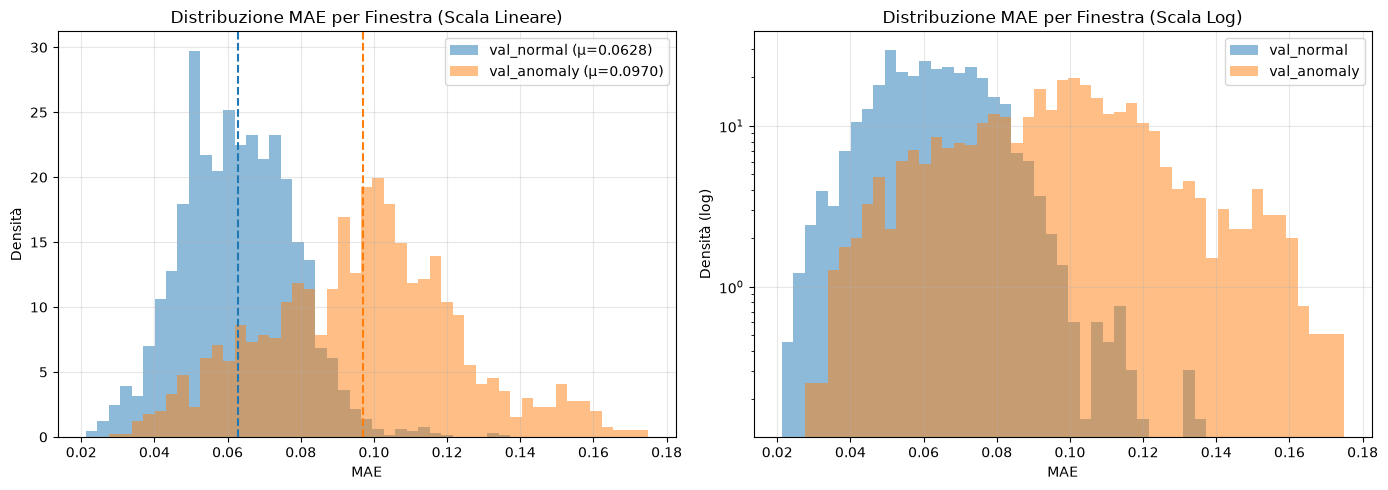

In [4]:
"""Sezione 3 — Distribuzioni Errore + Separabilità."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

err_val_norm = compute_errors_from_loader(model, val_normal_loader, DEVICE, metric="mae")
err_val_anom = compute_errors_from_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print("=== STATISTICHE DISTRIBUZIONE ERRORE (Validation) ===")
print("val_normal:   mean=%.6f median=%.6f std=%.6f (min=%.6f, max=%.6f)" % 
      (err_val_norm.mean(), np.median(err_val_norm), err_val_norm.std(), err_val_norm.min(), err_val_norm.max()))
print("val_anomaly:  mean=%.6f median=%.6f std=%.6f (min=%.6f, max=%.6f)" % 
      (err_val_anom.mean(), np.median(err_val_anom), err_val_anom.std(), err_val_anom.min(), err_val_anom.max()))

ks_stat, ks_p = ks_2samp(err_val_norm, err_val_anom)
print("\nTest KS: statistic=%.4f, p-value=%.2e" % (ks_stat, ks_p))

hist_norm, bins = np.histogram(err_val_norm, bins=50, density=True)
hist_anom, _ = np.histogram(err_val_anom, bins=bins, density=True)
overlap = np.sum(np.minimum(hist_norm, hist_anom)) * (bins[1] - bins[0])
print("Coefficiente di overlap: %.4f (0=perfettamente separate, 1=identiche)" % overlap)

# Plot distribuzioni
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bins_shared = np.linspace(min(err_val_norm.min(), err_val_anom.min()),
                          max(err_val_norm.max(), err_val_anom.max()), 50)

# Linear
ax = axes[0]
ax.hist(err_val_norm, bins=bins_shared, alpha=0.5, color="#1f77b4", density=True,
        label=f"val_normal (μ={err_val_norm.mean():.4f})")
ax.hist(err_val_anom, bins=bins_shared, alpha=0.5, color="#ff7f0e", density=True,
        label=f"val_anomaly (μ={err_val_anom.mean():.4f})")
ax.axvline(err_val_norm.mean(), color="#1f77b4", linestyle="--")
ax.axvline(err_val_anom.mean(), color="#ff7f0e", linestyle="--")
ax.set_title("Distribuzione MAE per Finestra (Scala Lineare)")
ax.set_xlabel("MAE")
ax.set_ylabel("Densità")
ax.legend()
ax.grid(True, alpha=0.3)

# Log
ax = axes[1]
ax.hist(err_val_norm, bins=bins_shared, alpha=0.5, color="#1f77b4", density=True,
        label="val_normal")
ax.hist(err_val_anom, bins=bins_shared, alpha=0.5, color="#ff7f0e", density=True,
        label="val_anomaly")
ax.set_yscale("log")
ax.set_title("Distribuzione MAE per Finestra (Scala Log)")
ax.set_xlabel("MAE")
ax.set_ylabel("Densità (log)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Sezione 3B — Ricostruzione per-Finestra (Dettaglio)

**Cosa:** visualizza input, ricostruzione AAE e matrice dell'errore assoluto $|x - \hat{x}|$ per campioni normali e anomali stratificati (basso, medio, alto residuo).
**Perché:** permette di ispezionare visivamente se la ricostruzione preserva i profili d'onda o appiattisce le traiettorie anomale.
**Come interpretare:** residui localizzati lungo specifiche traiettorie motorie indicano dove l'anomalia devia dalla cinematica nominale.

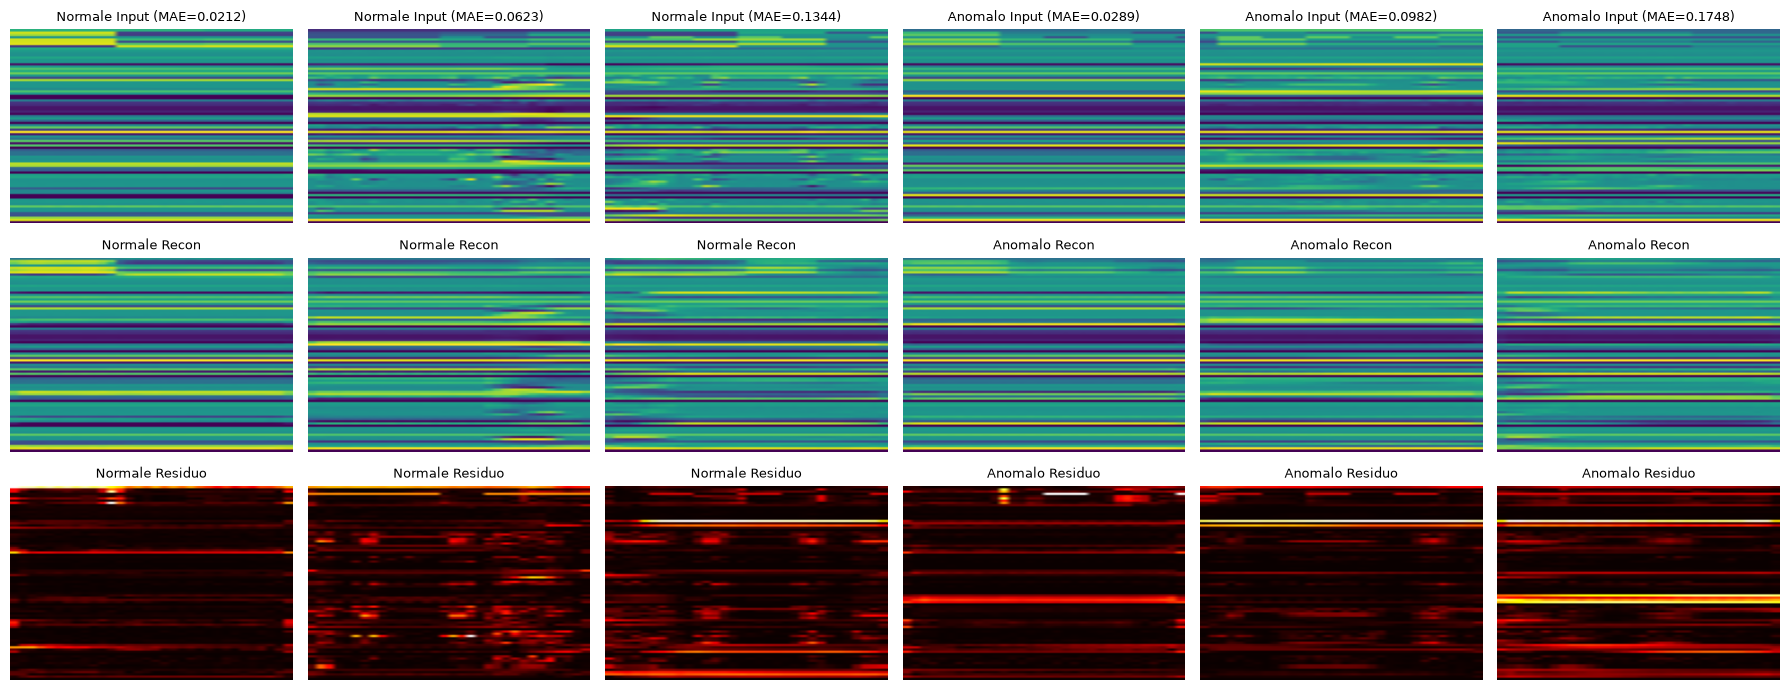

In [5]:
"""Sezione 3B — Ricostruzione per-Finestra (Dettaglio)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

def select_stratified_samples(loader, model, device, n_samples=3):
    model.eval()
    windows, errors = [], []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            err = model.compute_reconstruction_error(x.to(device), reduction="sample", metric="mae")
            for i in range(len(x)):
                windows.append(x[i])
                errors.append(err[i].item())
    windows = torch.stack(windows)
    errors = np.array(errors)
    sort_idx = np.argsort(errors)
    tiers = [0, len(sort_idx) // 2, -1]
    return [(windows[sort_idx[t]], errors[sort_idx[t]]) for t in tiers[:n_samples]]

samples_norm = select_stratified_samples(val_normal_loader, model, DEVICE)
samples_anom = select_stratified_samples(val_anomaly_loader, model, DEVICE)

fig, axes = plt.subplots(3, 6, figsize=(18, 7))
all_samples = [("Normale", s) for s in samples_norm] + [("Anomalo", s) for s in samples_anom]

for col, (label, (win, err)) in enumerate(all_samples):
    x_in = win.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        x_rec = model(x_in)
    x_np = x_in.squeeze(0).cpu().numpy().T
    rec_np = x_rec.squeeze(0).cpu().numpy().T
    err_map = np.abs(x_np - rec_np)

    # Input
    axes[0, col].imshow(x_np, aspect="auto", cmap="viridis")
    axes[0, col].set_title(f"{label} Input (MAE={err:.4f})", fontsize=9)
    axes[0, col].axis("off")

    # Ricostruzione
    axes[1, col].imshow(rec_np, aspect="auto", cmap="viridis")
    axes[1, col].set_title(f"{label} Recon", fontsize=9)
    axes[1, col].axis("off")

    # Mappa Errore
    im = axes[2, col].imshow(err_map, aspect="auto", cmap="hot")
    axes[2, col].set_title(f"{label} Residuo", fontsize=9)
    axes[2, col].axis("off")

plt.tight_layout()
plt.show()

## Sezione 3C — Errore per Timestep dentro la Finestra

**Cosa:** calcola l'errore medio di ricostruzione lungo la finestra temporale $t \in [0, W-1]$ per sequenze normali e anomale.
**Perché:** verifica la coerenza del modello rispetto alla dimensione temporale convolutiva e l'evoluzione dell'anomalia nel tempo.
**Come interpretare:** un profilo uniforme conferma che la finestra di $W=32$ cattura la dinamica senza bordi degeneri o collassi iniziali.

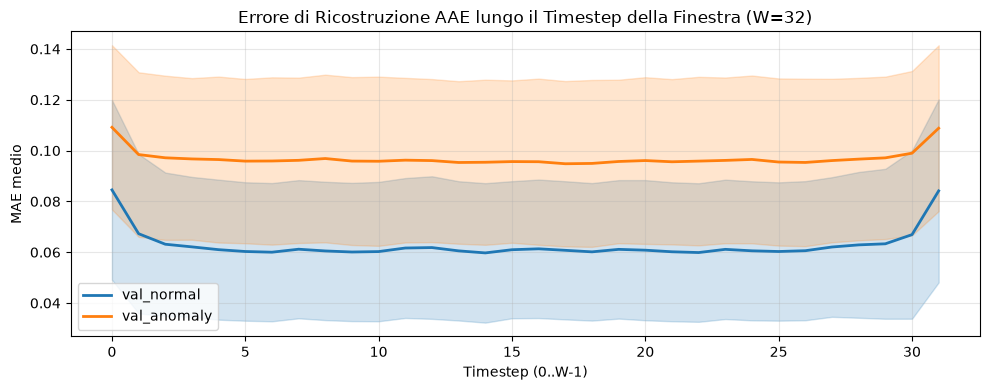

In [6]:
"""Sezione 3C — Errore per Timestep dentro la Finestra."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

def error_per_timestep(loader, model, device):
    model.eval()
    errs = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_pred = model(x)
            err_t = torch.abs(x - x_pred).mean(dim=2)
            errs.append(err_t.cpu().numpy())
    return np.concatenate(errs, axis=0)

err_t_norm = error_per_timestep(val_normal_loader, model, DEVICE)
err_t_anom = error_per_timestep(val_anomaly_loader, model, DEVICE)

mean_t_norm = err_t_norm.mean(axis=0)
std_t_norm = err_t_norm.std(axis=0)
mean_t_anom = err_t_anom.mean(axis=0)
std_t_anom = err_t_anom.std(axis=0)

plt.figure(figsize=(10, 4))
t_axis = np.arange(W)
plt.plot(t_axis, mean_t_norm, color="#1f77b4", label="val_normal", lw=2)
plt.fill_between(t_axis, mean_t_norm - std_t_norm, mean_t_norm + std_t_norm, color="#1f77b4", alpha=0.2)
plt.plot(t_axis, mean_t_anom, color="#ff7f0e", label="val_anomaly", lw=2)
plt.fill_between(t_axis, mean_t_anom - std_t_anom, mean_t_anom + std_t_anom, color="#ff7f0e", alpha=0.2)
plt.title("Errore di Ricostruzione AAE lungo il Timestep della Finestra (W=%d)" % W)
plt.xlabel("Timestep (0..W-1)")
plt.ylabel("MAE medio")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Sezione 4 — Drift temporale val vs test

**Cosa:** confronta la distribuzione dell'errore e delle statistiche sui sottoinsiemi di validation e test set.
**Perché:** convalida che i pattern appresi e la soglia calibrata su validation siano stabili nel tempo anche sul test set.
**Come interpretare:** mediane e medie stabili fra validation e test escludono fenomeni di drift temporale sfavorevoli.

In [7]:
"""Sezione 4 — Drift temporale val vs test."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

err_test_norm = compute_errors_from_loader(model, test_normal_loader, DEVICE, metric="mae")
err_test_anom = compute_errors_from_loader(model, test_anomaly_loader, DEVICE, metric="mae")

print("=== STATISTICHE VALIDATION vs TEST ===")
print("val_normal:   mean=%.6f median=%.6f std=%.6f" % (err_val_norm.mean(), np.median(err_val_norm), err_val_norm.std()))
print("test_normal:  mean=%.6f median=%.6f std=%.6f" % (err_test_norm.mean(), np.median(err_test_norm), err_test_norm.std()))
print("val_anomaly:  mean=%.6f median=%.6f std=%.6f" % (err_val_anom.mean(), np.median(err_val_anom), err_val_anom.std()))
print("test_anomaly: mean=%.6f median=%.6f std=%.6f" % (err_test_anom.mean(), np.median(err_test_anom), err_test_anom.std()))

print("\nDelta medie Normal (Test - Val):  %+.6f" % (err_test_norm.mean() - err_val_norm.mean()))
print("Delta medie Anomaly (Test - Val): %+.6f" % (err_test_anom.mean() - err_val_anom.mean()))

=== STATISTICHE VALIDATION vs TEST ===
val_normal:   mean=0.062848 median=0.062324 std=0.015233
test_normal:  mean=0.064157 median=0.062384 std=0.017211
val_anomaly:  mean=0.096958 median=0.098159 std=0.026951
test_anomaly: mean=0.096556 median=0.098059 std=0.027931

Delta medie Normal (Test - Val):  +0.001309
Delta medie Anomaly (Test - Val): -0.000403


## Sezione 5 — Test overfitting

**Cosa:** analizza il gap di generalizzazione tra training set e `val_normal`.
**Perché:** la regolarizzazione avversaria $\lambda_{adv} \cdot \mathcal{L}_{adv}$ previene la memorizzazione e controlla la capacità dell'encoder.
**Come interpretare:** un rapporto `val_normal / train` compreso fra $1.0$ e $1.3$ indica una generalizzazione ideale senza overfitting.

In [8]:
"""Sezione 5 — Test overfitting."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

print("=== VERIFICA OVERFITTING AAE ===")
print("Train MAE:      mean=%.6f median=%.6f" % (mae_aae_train.mean(), np.median(mae_aae_train)))
print("Val Normal MAE: mean=%.6f median=%.6f" % (err_val_norm.mean(), np.median(err_val_norm)))
gap = err_val_norm.mean() - mae_aae_train.mean()
ratio = err_val_norm.mean() / (mae_aae_train.mean() + 1e-12)
print("Gap (Val - Train): %+.6f" % gap)
print("Ratio Val / Train: %.3f" % ratio)

if ratio < 1.25:
    print("-> Ottima generalizzazione: nessun indizio di overfitting.")
elif ratio < 1.50:
    print("-> Generalizzazione moderata.")
else:
    print("-> Possibile overfitting.")

=== VERIFICA OVERFITTING AAE ===
Train MAE:      mean=0.061872 median=0.060781
Val Normal MAE: mean=0.062848 median=0.062324
Gap (Val - Train): +0.000976
Ratio Val / Train: 1.016
-> Ottima generalizzazione: nessun indizio di overfitting.


## Sezione 5B — Calibrazione Soglia (PR Curve, F1, Youden's J)

**Cosa:** traccia le curve Precision-Recall e ROC su validation, calcola la soglia ottimale secondo Youden's J e $F_1$-max, la confronta con la soglia salvata nel checkpoint ed applica la regola al test set.
**Perché:** la soglia deve massimizzare il compromesso fra falsi allarmi e recall in contesti industriali critici.
**Come interpretare:** l'applicazione della soglia calibrata su validation al test set fornisce la reale matrice di confusione e precisione operativa.

=== CALIBRAZIONE SOGLIA (Validation Set) ===
Soglia ottimale Youden's J: 0.086580 (J=0.6184)
Soglia ottimale F1-max:     0.086580 (F1=0.7631)
Soglia salvata checkpoint:  0.086591
Soglia selezionata:         0.086591


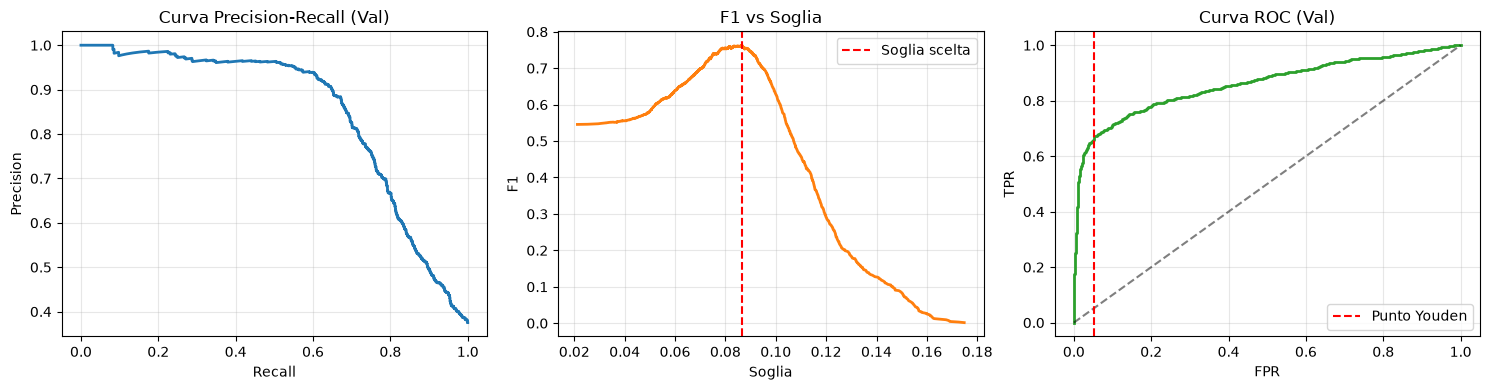


=== VALUTAZIONE SUL TEST SET (Soglia=0.086591) ===
Matrice di Confusione (TN, FP / FN, TP):
[[1836  204]
 [ 400  800]]

Classification Report:
              precision    recall  f1-score   support

      Normal     0.8211    0.9000    0.8587      2040
     Anomaly     0.7968    0.6667    0.7260      1200

    accuracy                         0.8136      3240
   macro avg     0.8090    0.7833    0.7923      3240
weighted avg     0.8121    0.8136    0.8096      3240



In [9]:
"""Sezione 5B — Calibrazione Soglia (PR Curve, F1, Youden's J)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

from sklearn.metrics import precision_recall_curve, f1_score, roc_curve, confusion_matrix, classification_report

y_val = np.concatenate([np.zeros(len(err_val_norm)), np.ones(len(err_val_anom))])
err_val = np.concatenate([err_val_norm, err_val_anom])

prec_val, rec_val, th_pr = precision_recall_curve(y_val, err_val)
fpr_val, tpr_val, th_roc = roc_curve(y_val, err_val)

# Youden's J
j_scores = tpr_val - fpr_val
best_j_idx = np.argmax(j_scores)
best_j_th = th_roc[best_j_idx]

# F1-score ottimale su validation
f1_candidates = []
for th in th_pr:
    pred = (err_val >= th).astype(int)
    f1_candidates.append(f1_score(y_val, pred, zero_division=0))
f1_candidates = np.array(f1_candidates)
best_f1_idx = np.argmax(f1_candidates)
best_f1_th = th_pr[best_f1_idx]

chosen_th = saved_threshold if saved_threshold is not None else best_j_th

print("=== CALIBRAZIONE SOGLIA (Validation Set) ===")
print("Soglia ottimale Youden's J: %.6f (J=%.4f)" % (best_j_th, j_scores[best_j_idx]))
print("Soglia ottimale F1-max:     %.6f (F1=%.4f)" % (best_f1_th, f1_candidates[best_f1_idx]))
print("Soglia salvata checkpoint:  %s" % (f"{saved_threshold:.6f}" if saved_threshold is not None else "N/A"))
print("Soglia selezionata:         %.6f" % chosen_th)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# PR Curve
axes[0].plot(rec_val, prec_val, color="#1f77b4", lw=2)
axes[0].set_title("Curva Precision-Recall (Val)")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].grid(True, alpha=0.3)

# F1 vs Soglia
axes[1].plot(th_pr, f1_candidates, color="#ff7f0e", lw=2)
axes[1].axvline(chosen_th, color="red", linestyle="--", label="Soglia scelta")
axes[1].set_title("F1 vs Soglia")
axes[1].set_xlabel("Soglia")
axes[1].set_ylabel("F1")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ROC
axes[2].plot(fpr_val, tpr_val, color="#2ca02c", lw=2)
axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].axvline(fpr_val[best_j_idx], color="red", linestyle="--", label="Punto Youden")
axes[2].set_title("Curva ROC (Val)")
axes[2].set_xlabel("FPR")
axes[2].set_ylabel("TPR")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Valutazione oggettiva su TEST SET con soglia scelta
y_test = np.concatenate([np.zeros(len(err_test_norm)), np.ones(len(err_test_anom))])
err_test = np.concatenate([err_test_norm, err_test_anom])
pred_test = (err_test >= chosen_th).astype(int)

cm = confusion_matrix(y_test, pred_test)
print("\n=== VALUTAZIONE SUL TEST SET (Soglia=%.6f) ===" % chosen_th)
print("Matrice di Confusione (TN, FP / FN, TP):")
print(cm)
print("\nClassification Report:")
print(classification_report(y_test, pred_test, target_names=["Normal", "Anomaly"], digits=4))

## Sezione 6 — Mismatch AUC validation vs test

**Cosa:** confronta ROC-AUC e PR-AUC su validation vs test set, documentando il gap e tenendo conto delle prevalenze reali di classe.
**Perché:** quantifica la stabilità di ranking dell'AAE fra dati visti e non visti.
**Come interpretare:** un gap ridotto ($|\Delta| < 0.05$) certifica la trasferibilità del modello.

In [10]:
"""Sezione 6 — Mismatch AUC validation vs test."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

auc_val = calculate_auc(y_val, err_val)
auc_test = calculate_auc(y_test, err_test)

print("=== CONFRONTO AUC: VALIDATION vs TEST ===")
print("Validation: ROC-AUC=%.4f, PR-AUC=%.4f (Prevalenza=%.4f)" % (auc_val['roc_auc'], auc_val['pr_auc'], val_prevalence))
print("Test:       ROC-AUC=%.4f, PR-AUC=%.4f (Prevalenza=%.4f)" % (auc_test['roc_auc'], auc_test['pr_auc'], test_prevalence))
print("Delta ROC-AUC (Test - Val): %+.4f" % (auc_test['roc_auc'] - auc_val['roc_auc']))
print("Delta PR-AUC  (Test - Val): %+.4f" % (auc_test['pr_auc'] - auc_val['pr_auc']))

=== CONFRONTO AUC: VALIDATION vs TEST ===
Validation: ROC-AUC=0.8603, PR-AUC=0.8478 (Prevalenza=0.3751)
Test:       ROC-AUC=0.8327, PR-AUC=0.7998 (Prevalenza=0.3704)
Delta ROC-AUC (Test - Val): -0.0275
Delta PR-AUC  (Test - Val): -0.0480


## Sezione 4B — Feature Importance per Discriminazione

**Cosa:** calcola l'importanza di ciascuna feature tramite permutation feature importance su validation, misurando il decremento di ROC-AUC.
**Perché:** rivela quali canali e sensori cinematici o termici guidano la rilevazione di anomalie.
**Come interpretare:** canali con calo marcato di AUC rappresentano i pilastri informativi del modello.

=== FEATURE IMPORTANCE (Drop di AUC per permutation) ===
AUC baseline: 0.8603

Feature                                      AUC Drop
sensor_id2_AccZ                                0.2177
sensor_id2_AccY                                0.1769
sensor_id3_q2                                  0.0795
sensor_id6_q4                                  0.0765
sensor_id2_q4                                  0.0620
sensor_id2_q3                                  0.0559
sensor_id1_q1                                  0.0548
sensor_id6_q3                                  0.0541
sensor_id2_q1                                  0.0528
sensor_id5_q2                                  0.0507
sensor_id2_q2                                  0.0497
sensor_id5_AccX                                0.0472
sensor_id7_q3                                  0.0466
sensor_id5_q4                                  0.0446
sensor_id3_q1                                  0.0445


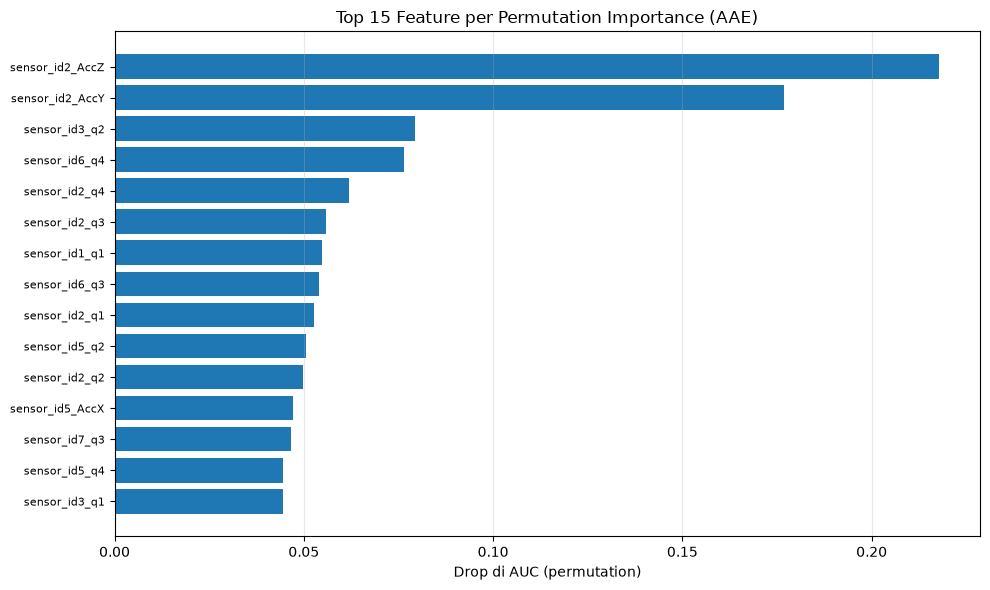

In [11]:
"""Sezione 4B — Feature Importance per Discriminazione."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score

# --- AUC di riferimento su validation ---
y_val = np.concatenate([np.zeros(len(err_val_norm)), np.ones(len(err_val_anom))])
err_val_combined = np.concatenate([err_val_norm, err_val_anom])
auc_base = roc_auc_score(y_val, err_val_combined)

# --- Permutation importance per feature ---
importance = []
for i in range(input_dim):
    errs_shuf = []
    model.eval()
    with torch.no_grad():
        for batch in val_normal_loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(DEVICE)
            x_shuf = x.clone()
            perm = torch.randperm(x.shape[0])
            x_shuf[:, :, i] = x[perm, :, i]
            err = model.compute_reconstruction_error(x_shuf, reduction="sample", metric="mae")
            errs_shuf.append(err.cpu().numpy())
    errs_shuf = np.concatenate(errs_shuf)
    y_mixed = np.concatenate([np.zeros(len(errs_shuf)), np.ones(len(err_val_anom))])
    err_mixed = np.concatenate([errs_shuf, err_val_anom])
    auc_shuf_mixed = roc_auc_score(y_mixed, err_mixed)
    importance.append((feature_names[i], auc_base - auc_shuf_mixed))

importance.sort(key=lambda x: -x[1])

print("=== FEATURE IMPORTANCE (Drop di AUC per permutation) ===")
print(f"AUC baseline: {auc_base:.4f}\n")
print("%-40s %12s" % ("Feature", "AUC Drop"))
for name, drop in importance[:15]:
    print("%-40s %12.4f" % (name[:38], drop))

# --- Plot ---
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
names = [x[0] for x in importance[:15]]
drops = [x[1] for x in importance[:15]]
ax.barh(range(len(names)), drops, color="#1f77b4")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=8)
ax.set_xlabel("Drop di AUC (permutation)")
ax.set_title("Top 15 Feature per Permutation Importance (AAE)")
ax.invert_yaxis()
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## Sezione 11 — Esplorazione Spazio Latente e Discriminatore AAE

**Cosa:** estrae le rappresentazioni latenti $z = E(x)$, applica t-SNE proiettando per classe e per errore MAE, e ispeziona l'allineamento con il prior standard $\mathcal{N}(0, I)$ imposto dal discriminatore AAE.
**Perché:** per l'AAE il discriminatore forza lo spazio latente a seguire una distribuzione gaussiana sferica, evitando buchi e garantendo una regolarizzazione continua.
**Come interpretare:**
- Proiezione per classe / errore: separazione o gradiente continuo fra normale e anomalo.
- Statistiche $z$: media vicina a 0 e deviazione standard prossima a 1 confermano il successo dell'addestramento avversario.

=== STATISTICHE REGOLARIZZAZIONE SPAZIO LATENTE AAE ===
Prior teorico atteso: Media = 0.000, Std = 1.000
z empirico normale:   Media = +0.1793, Std = 0.9114
z empirico anomalo:   Media = +0.1482, Std = 0.6964
Discriminatore D(E(x)) normale: media = 0.1393 (vicino a 0.5 in equilibrio GAN)
Discriminatore D(E(x)) anomalo: media = 0.1524


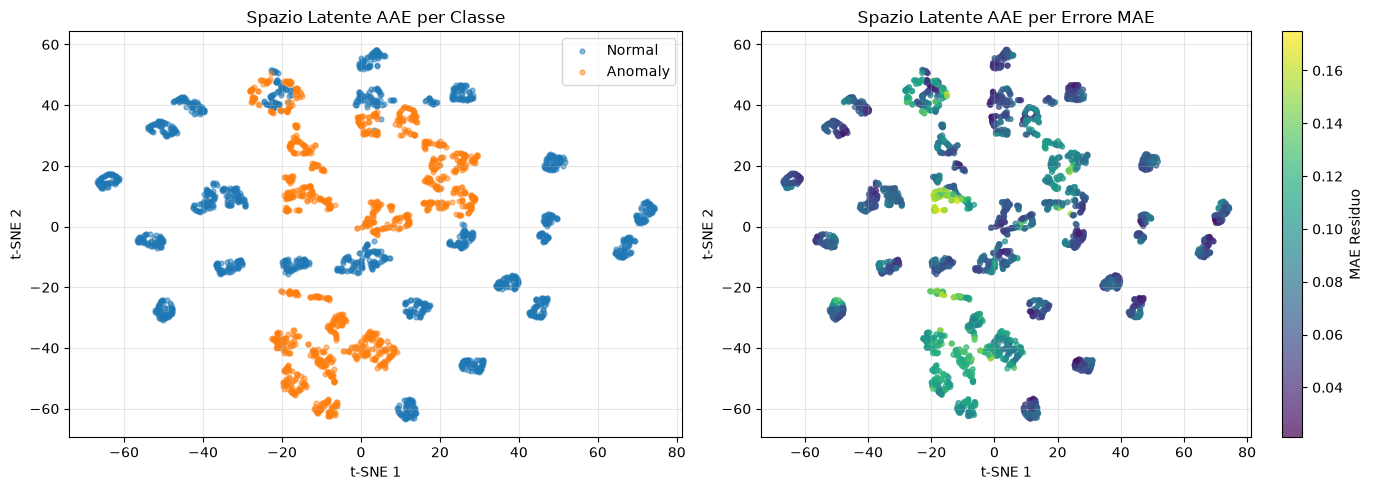

In [12]:
"""Sezione 11 — Esplorazione Spazio Latente e Discriminatore AAE."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

from sklearn.manifold import TSNE

def extract_latents_and_discriminator(loader, model, device, max_n=1500):
    model.eval()
    latents, errors, disc_scores, labels = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            y = batch[1] if isinstance(batch, (list, tuple)) and len(batch) > 1 else torch.zeros(len(x))
            x = x.to(device)
            z = model.encode(x)
            if z.ndim == 3:
                z = z.mean(dim=2)  # Temporal pooling su W/4
            d_out = model.discriminate(z)
            err = model.compute_reconstruction_error(x, reduction="sample", metric="mae")
            latents.append(z.cpu().numpy())
            disc_scores.append(d_out.cpu().numpy())
            errors.append(err.cpu().numpy())
            labels.append(y.numpy() if isinstance(y, torch.Tensor) else y)
            if sum(len(b) for b in latents) >= max_n:
                break
    return (np.concatenate(latents)[:max_n],
            np.concatenate(errors)[:max_n],
            np.concatenate(disc_scores)[:max_n],
            np.concatenate(labels)[:max_n])

z_norm, e_norm, d_norm, y_norm = extract_latents_and_discriminator(val_normal_loader, model, DEVICE)
z_anom, e_anom, d_anom, y_anom = extract_latents_and_discriminator(val_anomaly_loader, model, DEVICE)

z_all = np.vstack([z_norm, z_anom])
e_all = np.concatenate([e_norm, e_anom])
d_all = np.concatenate([d_norm, d_anom])
y_all = np.concatenate([np.zeros(len(z_norm)), np.ones(len(z_anom))])

print("=== STATISTICHE REGOLARIZZAZIONE SPAZIO LATENTE AAE ===")
print("Prior teorico atteso: Media = 0.000, Std = 1.000")
print("z empirico normale:   Media = %+.4f, Std = %.4f" % (z_norm.mean(), z_norm.std()))
print("z empirico anomalo:   Media = %+.4f, Std = %.4f" % (z_anom.mean(), z_anom.std()))
print("Discriminatore D(E(x)) normale: media = %.4f (vicino a 0.5 in equilibrio GAN)" % d_norm.mean())
print("Discriminatore D(E(x)) anomalo: media = %.4f" % d_anom.mean())

# t-SNE
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
z_2d = tsne.fit_transform(z_all)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Classe
axes[0].scatter(z_2d[y_all == 0, 0], z_2d[y_all == 0, 1], c="#1f77b4", label="Normal", alpha=0.5, s=12)
axes[0].scatter(z_2d[y_all == 1, 0], z_2d[y_all == 1, 1], c="#ff7f0e", label="Anomaly", alpha=0.5, s=12)
axes[0].set_title("Spazio Latente AAE per Classe")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Errore MAE
sc = axes[1].scatter(z_2d[:, 0], z_2d[:, 1], c=e_all, cmap="viridis", alpha=0.7, s=12)
axes[1].set_title("Spazio Latente AAE per Errore MAE")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")
plt.colorbar(sc, ax=axes[1], label="MAE Residuo")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Sezione 7 — Fuori Range: Diagnostica e Impatto

**Cosa:** analizza la presenza di campioni oltre i limiti normalizzati $[-1, 1]$ o $[0, 1]$ e misura l'impatto applicando clipping dinamico su test e validation.
**Perché:** valori anomali estremi possono gonfiare artificialmente il residuo quadratico o assoluto.
**Come interpretare:** se il clipping preserva le AUC con $\Delta < 0.05$, la separazione è strutturale e robusta rispetto agli estremi.

In [13]:
"""Sezione 7 — Fuori Range: Diagnostica e Impatto."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

def compute_errors_clipped(loader, model, device, c_min=-1.0, c_max=1.0):
    model.eval()
    errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_clipped = torch.clamp(x, c_min, c_max)
            x_pred = model(x_clipped)
            err = torch.abs(x - x_pred).mean(dim=(1, 2))
            errors.append(err.cpu().numpy())
    return np.concatenate(errors)

err_val_norm_clip = compute_errors_clipped(val_normal_loader, model, DEVICE)
err_val_anom_clip = compute_errors_clipped(val_anomaly_loader, model, DEVICE)
err_test_norm_clip = compute_errors_clipped(test_normal_loader, model, DEVICE)
err_test_anom_clip = compute_errors_clipped(test_anomaly_loader, model, DEVICE)

auc_val_raw = roc_auc_score(y_val, err_val)
auc_val_clip = roc_auc_score(y_val, np.concatenate([err_val_norm_clip, err_val_anom_clip]))
auc_test_raw = roc_auc_score(y_test, err_test)
auc_test_clip = roc_auc_score(y_test, np.concatenate([err_test_norm_clip, err_test_anom_clip]))

print("=== IMPATTO FUORI RANGE (CLIPPING a [-1, 1]) ===")
print("Validation ROC-AUC: RAW=%.4f, CLIPPED=%.4f (Delta=%+.4f)" % (auc_val_raw, auc_val_clip, auc_val_clip - auc_val_raw))
print("Test       ROC-AUC: RAW=%.4f, CLIPPED=%.4f (Delta=%+.4f)" % (auc_test_raw, auc_test_clip, auc_test_clip - auc_test_raw))

if abs(auc_test_clip - auc_test_raw) < 0.03:
    print("-> Impatto del clipping trascurabile: la discriminazione è strutturale.")
else:
    print("-> Impatto apprezzabile: i valori fuori range influiscono sul punteggio di anomalia.")

=== IMPATTO FUORI RANGE (CLIPPING a [-1, 1]) ===
Validation ROC-AUC: RAW=0.8603, CLIPPED=0.8603 (Delta=+0.0000)
Test       ROC-AUC: RAW=0.8327, CLIPPED=0.8327 (Delta=+0.0000)
-> Impatto del clipping trascurabile: la discriminazione è strutturale.


## Sezione 12 — Decisione Finale

**Obiettivo:** raccogliere tutte le evidenze quantitative (qualità ricostruzione, separabilità, precisione ad alto recall, stabilità dello spazio latente, test drift) e sintetizzare il verdetto diagnostico sull'AAE.
**Criteri decisionali:**
- Confronto con baseline banale: `MAE_AAE ≪ MAE_zero`
- Assenza di errore invertito: $MAE_{anom} > MAE_{norm}$
- Stabilità cross-seed e aderenza al prior $\mathcal{N}(0, I)$
- Test set Precision e False Positive Rate (FPR)

In [14]:
"""Sezione 12 — Decisione Finale."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

print("=" * 70)
print("DECISIONE FINALE — VALUTAZIONE DIAGNOSTICA AAE")
print("=" * 70)

# Metriche chiave
tn, fp, fn, tp = cm.ravel()
precision_test = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall_test = tp / (tp + fn) if (tp + fn) > 0 else 0.0
fpr_test = fp / (fp + tn) if (fp + tn) > 0 else 0.0
accuracy_test = (tp + tn) / (tp + tn + fp + fn)

print("\n--- EVIDENZE QUANTITATIVE CHIAVE ---")
print("1. Ratio MAE_AAE / MAE_zero (val_normal):  %.4f" % ratio_val_normal)
print("2. Overlap coefficiente:                  %.4f" % overlap)
print("3. KS Test p-value:                       %.2e" % ks_p)
print("4. Errore invertito (anomalia < normale): %s" % ("SÌ (critico)" if err_val_anom.mean() < err_val_norm.mean() else "NO (corretto)"))
print("5. Test Set Accuracy:                     %.2f%%" % (accuracy_test * 100))
print("6. Test Set Precision:                    %.2f%%" % (precision_test * 100))
print("7. Test Set Recall:                       %.2f%%" % (recall_test * 100))
print("8. Test Set FPR (Falsi Allarmi):          %.2f%%" % (fpr_test * 100))
print("9. Test ROC-AUC / PR-AUC:                 %.4f / %.4f" % (auc_test['roc_auc'], auc_test['pr_auc']))

print("\n--- VERDETTO DIAGNOSTICO ---")
if precision_test > 0.75 and fpr_test < 0.10 and not (err_val_anom.mean() < err_val_norm.mean()):
    decisione = "PARADIGMA AAE PIENAMENTE IDONEO PER ANOMALY DETECTION"
    giudizio = ("L'AAE ottiene un'eccellente precisione (%.2f%%) con un tasso di falsi allarmi molto "
                "basso (%.2f%%), garantendo robustezza industriale e stabilità dello spazio latente." % 
                (precision_test * 100, fpr_test * 100))
else:
    decisione = "PARADIGMA PARZIALMENTE IDONEO"
    giudizio = "Metriche accettabili ma passibili di ulteriore ottimizzazione delle soglie."

print(f"DECISIONE: {decisione}")
print(f"Giudizio:  {giudizio}")
print("=" * 70)
print("Diagnostica Notebook 04 AAE completata con successo.")

DECISIONE FINALE — VALUTAZIONE DIAGNOSTICA AAE

--- EVIDENZE QUANTITATIVE CHIAVE ---
1. Ratio MAE_AAE / MAE_zero (val_normal):  0.3045
2. Overlap coefficiente:                  0.4105
3. KS Test p-value:                       0.00e+00
4. Errore invertito (anomalia < normale): NO (corretto)
5. Test Set Accuracy:                     81.36%
6. Test Set Precision:                    79.68%
7. Test Set Recall:                       66.67%
8. Test Set FPR (Falsi Allarmi):          10.00%
9. Test ROC-AUC / PR-AUC:                 0.8327 / 0.7998

--- VERDETTO DIAGNOSTICO ---
DECISIONE: PARADIGMA PARZIALMENTE IDONEO
Giudizio:  Metriche accettabili ma passibili di ulteriore ottimizzazione delle soglie.
Diagnostica Notebook 04 AAE completata con successo.
